### 서울시 주유 가격 데이터 분석
* 오피넷의 데이터를 이용 서울시 주유소 가격 데이터를 정리하고 시각화

## 1. 라이브러리 불러오기

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager, rc

## 2. 오피넷 엑셀 파일 불러오기

In [3]:
data_dir = Path("../data")
stations_files = sorted(data_dir.glob("지역_위치별*xls"))
stations_files[:5], len(stations_files)

([WindowsPath('../data/지역_위치별(주유소) (1).xls'),
  WindowsPath('../data/지역_위치별(주유소) (10).xls'),
  WindowsPath('../data/지역_위치별(주유소) (11).xls'),
  WindowsPath('../data/지역_위치별(주유소) (12).xls'),
  WindowsPath('../data/지역_위치별(주유소) (13).xls')],
 25)

In [4]:
!pip install xlrd

In [7]:
raw_list = [pd.read_excel(file, header = 2) for file in stations_files]
station_raw = pd.concat(raw_list, ignore_index=True)
station_raw.head()

,지역,상호,주소,상표,전화번호,셀프여부,고급휘발유,휘발유,경유,실내등유
0,서울특별시,오렌지주유소,서울 강동구 성안로 102 (성내동),SK에너지,02-484-6165,N,-,1554,1354,997
1,서울특별시,구천면주유소,서울 강동구 구천면로 357 (암사동),현대오일뱅크,02-441-0536,N,-,1556,1355,-
2,서울특별시,GS칼텍스㈜직영 신월주유소,서울 강동구 양재대로 1323 (성내동),GS칼텍스,02-475-2600,N,1855,1559,1349,1000
3,서울특별시,광성주유소,서울 강동구 올림픽로 673 (천호동),S-OIL,02-470-5133,N,-,1578,1388,1100
4,서울특별시,(주)소모에너지엔테크놀러지성내주유소,서울 강동구 올림픽로 578 (성내동),GS칼텍스,02-479-3838,Y,-,1588,1388,-


In [10]:
raw_list = [pd.read_excel(file, header = 2) for file in stations_files]
station_raw = pd.concat(raw_list, ignore_index=True)
station_raw.tail(1)

,지역,상호,주소,상표,전화번호,셀프여부,고급휘발유,휘발유,경유,실내등유
536,서울특별시,뉴서울(강남),서울 강남구 언주로 716 (논현동),SK에너지,02-518-5631,N,2420,2120,1920,1330


In [36]:
station_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 537 entries, 0 to 536
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   지역      537 non-null    object
 1   상호      537 non-null    object
 2   주소      537 non-null    object
 3   상표      537 non-null    object
 4   전화번호    537 non-null    object
 5   셀프여부    537 non-null    object
 6   고급휘발유   537 non-null    object
 7   휘발유     537 non-null    object
 8   경유      537 non-null    object
 9   실내등유    537 non-null    object
dtypes: object(10)
memory usage: 42.1+ KB


## 3. 필요한 컬럼만 선택하고 컬럼명 정리

In [37]:
stations = (
    station_raw.loc[:, ["상호", "주소", "휘발유", "셀프여부", "상표"]] #행, 열
)
stations.head()

,상호,주소,휘발유,셀프여부,상표
0,오렌지주유소,서울 강동구 성안로 102 (성내동),1554,N,SK에너지
1,구천면주유소,서울 강동구 구천면로 357 (암사동),1556,N,현대오일뱅크
2,GS칼텍스㈜직영 신월주유소,서울 강동구 양재대로 1323 (성내동),1559,N,GS칼텍스
3,광성주유소,서울 강동구 올림픽로 673 (천호동),1578,N,S-OIL
4,(주)소모에너지엔테크놀러지성내주유소,서울 강동구 올림픽로 578 (성내동),1588,Y,GS칼텍스


In [38]:
stations = (
    station_raw
    .loc[:, ["상호", "주소", "휘발유", "셀프여부", "상표"]] #행, 열
    .rename(columns={"상호":"Oil_store", "휘발유":"가격", "셀프여부":"셀프"}))
stations.head(1)

,Oil_store,주소,가격,셀프,상표
0,오렌지주유소,서울 강동구 성안로 102 (성내동),1554,N,SK에너지


## 4. 주소에서 구 이름 추출

In [39]:
stations = stations.assign(
    구 = stations["주소"].astype(str).str.split().str[1])
stations.head(1)

,Oil_store,주소,가격,셀프,상표,구
0,오렌지주유소,서울 강동구 성안로 102 (성내동),1554,N,SK에너지,강동구


In [40]:
# 구 이름이 맞는지 확인
# 서울특별시 강동구, 서울 특별시, 서울특별시
stations["구"].unique()

array(['강동구', '동대문구', '동작구', '마포구', '서대문구', '서초구', '성동구', '서울특별시', '성북구',
       '송파구', '양천구', '영등포구', '강북구', '용산구', '은평구', '종로구', '중구', '중랑구',
       '강서구', '관악구', '광진구', '구로구', '금천구', '노원구', '도봉구', '특별시', '강남구'],
      dtype=object)

In [43]:
#잘못된 구 수정
gu_fix_map = {
    "서울특별시" : "성동구",
    "특별시" : "도봉구"}

stations = stations.assign(
    구 = stations["구"].replace(gu_fix_map))

In [44]:
stations["구"].unique()

array(['강동구', '동대문구', '동작구', '마포구', '서대문구', '서초구', '성동구', '성북구', '송파구',
       '양천구', '영등포구', '강북구', '용산구', '은평구', '종로구', '중구', '중랑구', '강서구',
       '관악구', '광진구', '구로구', '금천구', '노원구', '도봉구', '강남구'], dtype=object)

## 5. 가격 데이터 정리

In [46]:
stations[stations["가격"].eq("-")].head(1)

,Oil_store,주소,가격,셀프,상표,구
18,명진석유(주)동서울주유소,서울특별시 강동구 천호대로 1456 (상일동),-,Y,GS칼텍스,강동구


In [47]:
stations = (
    #errors = "coerce" 숫자로 바꿀 수 없는 값이 있으면 오류를 내지 않고 NAN으로 변경
    stations.assign(가격 = pd.to_numeric(stations["가격"].replace("-", np.nan), errors = "coerce"))
    .dropna(subset=["가격"]) # 가격 NAN인 행 삭제
    .reset_index(drop = True)) # 인덱스 0인 행 삭제

stations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 533 entries, 0 to 532
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Oil_store  533 non-null    object 
 1   주소         533 non-null    object 
 2   가격         533 non-null    float64
 3   셀프         533 non-null    object 
 4   상표         533 non-null    object 
 5   구          533 non-null    object 
dtypes: float64(1), object(5)
memory usage: 25.1+ KB


In [49]:
stations.head(1)

,Oil_store,주소,가격,셀프,상표,구
0,오렌지주유소,서울 강동구 성안로 102 (성내동),1554.0,N,SK에너지,강동구


## 6. 한글 폰트 설정

In [57]:
plt.rcParams["axes.unicode_minus"] = False

font_path = Path("C:/Windows/Fonts/malgun.ttf")
# font_path = Path("/System/Library/Fonts/Supplemental/AppleGothic.ttf")

if font_path.exists():
    font_name = font_manager.FontProperties(fname=str(font_path)).get_name()
    rc("font", family=font_name)
else:
    print("한글 폰트 파일을 찾지 못했습니다. 필요하면 font_path를 수정하세요.")

## 7. 셀프 주요소 가격 비교

In [58]:
# 그래프 반복 호출로 생기는 경고 감추기
import warnings
warnings.filterwarnings('ignore')

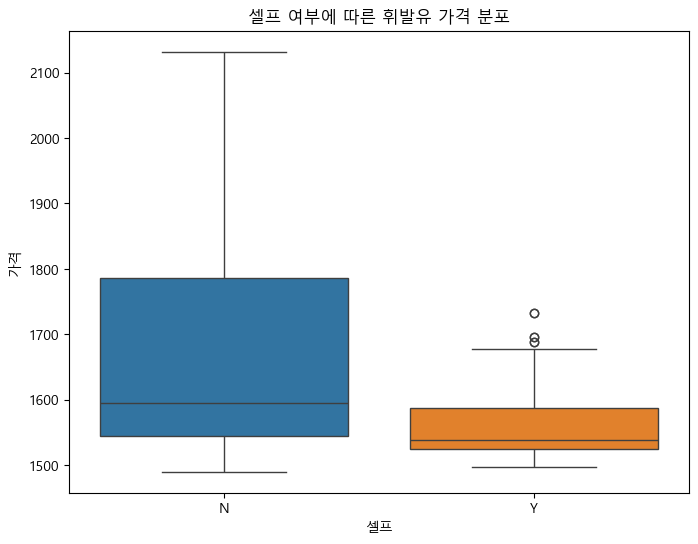

In [59]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=stations, x = "셀프", y = "가격", hue = "셀프", legend = False)
plt.title("셀프 여부에 따른 휘발유 가격 분포")
plt.show()

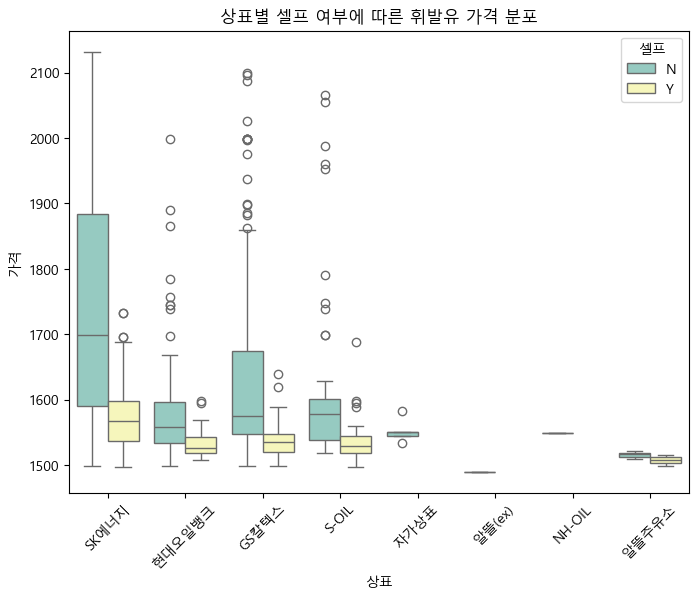

In [61]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=stations, x = "상표", y = "가격", hue = "셀프", palette="Set3")
plt.title("상표별 셀프 여부에 따른 휘발유 가격 분포")
plt.xticks(rotation = 45)
plt.show()

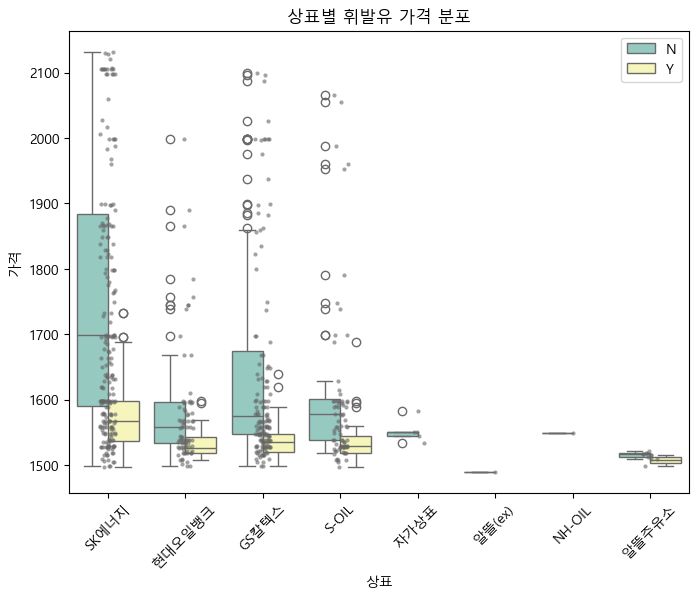

In [63]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=stations, x = "상표", y = "가격", hue = "셀프", palette="Set3")
sns.stripplot(data = stations, x = "상표", y = "가격", color = "0.4", size = 3, alpha = 0.6)
plt.title("상표별 휘발유 가격 분포")
plt.xticks(rotation = 45)
plt.show()

## 8. 가격 상위 / 하위 주유소 확인

In [65]:
stations.sort_values(by = "가격", ascending = False).head(10)

,Oil_store,주소,가격,셀프,상표,구
325,서남주유소,서울 중구 통일로 30 (봉래동1가),2132.0,N,SK에너지,중구
324,장충주유소,서울 중구 장충단로 202 (장충동1가),2130.0,N,SK에너지,중구
124,양재주유소,서울 서초구 바우뫼로 178 (양재동),2128.0,N,SK에너지,서초구
532,뉴서울(강남),서울 강남구 언주로 716 (논현동),2120.0,N,SK에너지,강남구
531,오천주유소,서울 강남구 봉은사로 503 (삼성동),2107.0,N,SK에너지,강남구
284,갈월동주유소,서울특별시 용산구 한강대로 322 (갈월동),2106.0,N,SK에너지,용산구
285,청파주유소,서울특별시 용산구 청파로 311 (청파동1가),2106.0,N,SK에너지,용산구
530,삼성주유소,서울 강남구 삼성로 521 (삼성동),2106.0,N,SK에너지,강남구
313,재동주유소,서울특별시 종로구 율곡로 58 (경운동),2106.0,N,SK에너지,종로구
283,강변주유소,서울특별시 용산구 원효로 9 (청암동),2106.0,N,SK에너지,용산구


In [66]:
stations.sort_values(by = "가격", ascending = True).head(10)

,Oil_store,주소,가격,셀프,상표,구
83,만남의광장주유소,서울 서초구 양재대로12길 73-71 (원지동),1490.0,N,알뜰(ex),서초구
344,강서오곡셀프주유소,서울특별시 강서구 벌말로 254 (오곡동),1497.0,Y,SK에너지,강서구
451,태릉솔밭주유소,서울특별시 노원구 노원로 49 (공릉동),1497.0,Y,S-OIL,노원구
258,수유동주유소,서울특별시 강북구 도봉로 395 (수유동),1498.0,Y,GS칼텍스,강북구
326,신일셀프주유소,서울 중랑구 상봉로 58 (망우동),1499.0,Y,SK에너지,중랑구
226,(주)대청에너지 대청주유소,서울 영등포구 가마산로 328 (대림동),1499.0,N,GS칼텍스,영등포구
225,도림주유소,서울 영등포구 도림로 343 (도림동),1499.0,Y,알뜰주유소,영등포구
227,(주)강서오일,서울 영등포구 도신로 151 (도림동),1499.0,N,현대오일뱅크,영등포구
415,풀페이주유소,서울특별시 구로구 경인로 41 (온수동),1499.0,N,SK에너지,구로구
40,서경주유소,서울 동작구 대림로 46 (신대방동),1499.0,N,현대오일뱅크,동작구


## 9. 구별 평균 가격 확인

In [67]:
gu_price = (
    stations.groupby("구", as_index = False)
    .agg(평균가격 = ("가격", "mean"), 주유소수 = ("Oil_store", "count"))
    .sort_values("평균가격", ascending = False))
gu_price.head()

,구,평균가격,주유소수
23,중구,1964.083333,12
20,용산구,1946.312500,16
22,종로구,1941.777778,9
0,강남구,1791.000000,46
12,마포구,1698.928571,14


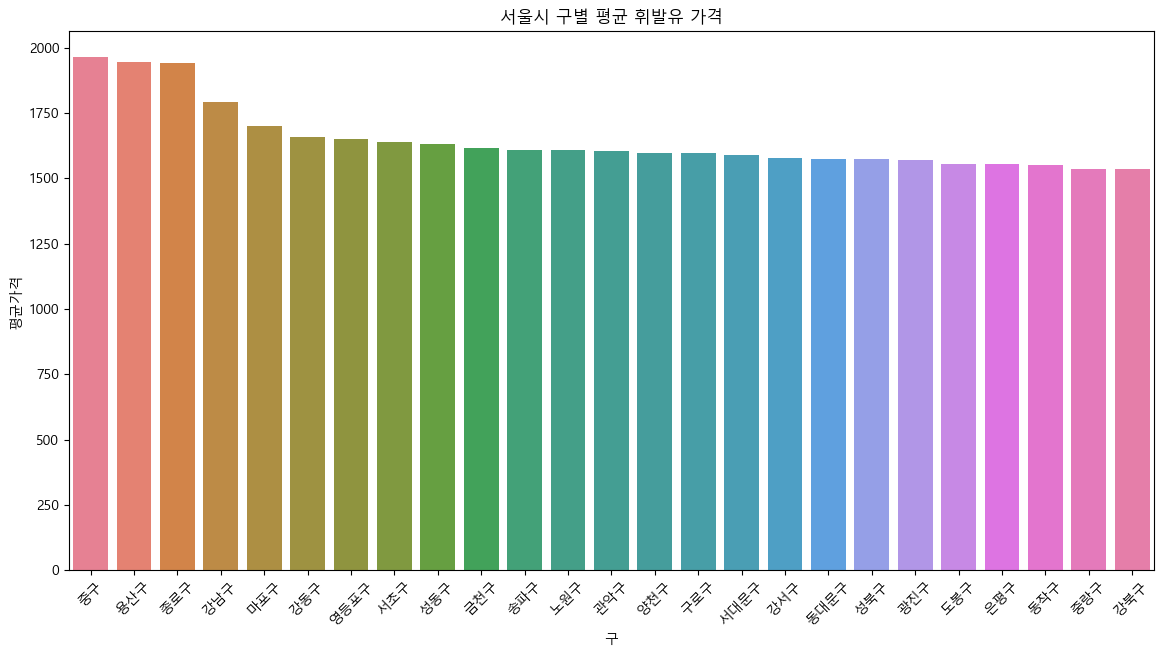

In [70]:
plt.figure(figsize=(14, 7))
sns.barplot(data=gu_price, x = "구", y = "평균가격", hue = "구")
plt.title("서울시 구별 평균 휘발유 가격")
plt.xticks(rotation = 45)
plt.show()

## 10. 정리된 데이터 저장

In [71]:
output_dir = Path("../output")
output_dir.mkdir(exist_ok=True)

stations.to_csv(output_dir / "seoul_oil_price.csv", index=False, encoding="utf-8-sig")
gu_price.to_csv(output_dir / "seoul_oil_price_by_gu.csv", index=False, encoding="utf-8-sig")

print("저장완료")

저장완료


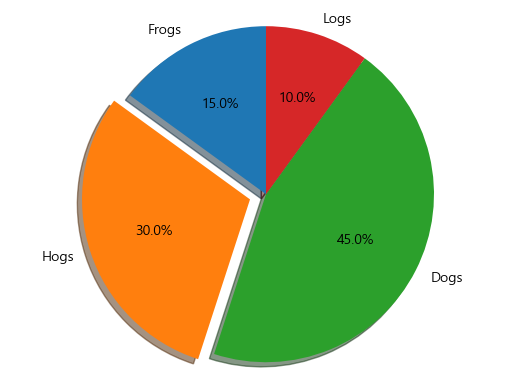

In [72]:
import matplotlib.pyplot as plt

labels = 'Frogs', 'Hogs', 'Dogs', 'Logs'
sizes = [15, 30, 45, 10]
explode = (0, 0.1, 0, 0) # only "explode" the 2nd slice (i.e. 'Hogs')

fig1, ax1 = plt.subplots()
ax1.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%',
shadow=True, startangle=90)
ax1.axis('equal')
plt.show()

## 퀴즈
1. data\names를 이용하여 2000~20009까지 출생한 남여 출생 수를 파이 차트로 그리기

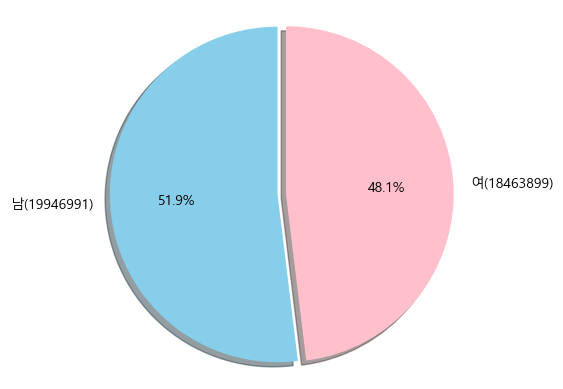

In [82]:
data_dir = Path("../data/names")

df = pd.concat([pd.read_csv(data_dir / f"yob{y}.txt", names=["name", "sex", "births"]).assign(year=y)
                for y in range(2000, 2010)])

births = df.groupby("sex")["births"].sum()
labels = [f"남({births['M']})", f"여({births['F']})"]
sizes = [births["M"], births["F"]]

fig1, ax1 = plt.subplots()
ax1.pie(sizes, explode=(0, 0.05), labels=labels, autopct='%1.1f%%',
        shadow=True, startangle=90, colors=["skyblue", "pink"])
ax1.axis('equal')
plt.show()

2. 연도별 남여/ 숫자를 그래프로 그려 보세요.

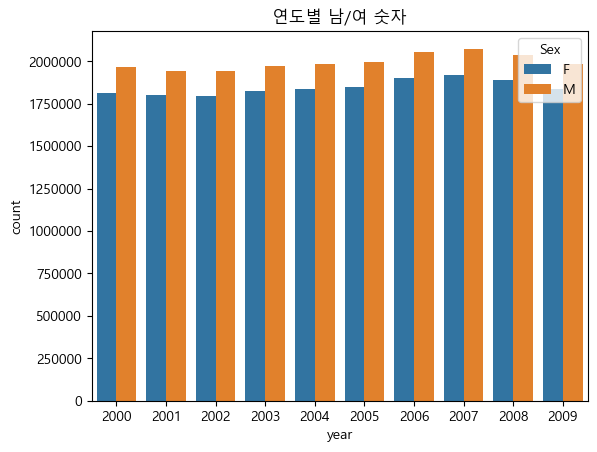

In [91]:
fig2, ax2 = plt.subplots()
sns.barplot(data=year_sex, x="year", y="births", hue="sex", ax=ax2)
ax2.set_title("연도별 남/여 숫자")
ax2.set_ylabel("count")
ax2.ticklabel_format(axis="y", style="plain")
ax2.legend(title="Sex")
plt.show()